Use the following to explore the FFT of a simple function:

$f\left(t\right)=a\:\sin\left(f_12\pi t\right)+b\:\sin\left(f_22\pi t\right)+c\:\cos\left(f_32\pi t\right)+d\:\cos\left(f_42\pi t\right)+e $

Fill in the blanks and try different frequencies ($f_1, f_2, f_3, f_4$) and combinations of sine and cosine functions to create f. Since we've designed this function to just be a sum of a few sin and cos functions, we should get back what we put in.

First run this preamble to load necessary modules

In [ ]:
from numpy import linspace,array,zeros,log,exp,sin,cos,sqrt,pi,e, arange, real, imag
from matplotlib.pyplot import plot,xlabel,ylabel,legend,show, figure, subplot
from scipy.fftpack import fft

Now create a time array given a sample rate, Fs, and the number of observations, nt. This is typical specification for a time series, and we can get the time interval between observations and the total lenght of the time series from these two numbers.

In [2]:
# time dimension

Fs = 500 # Hz  sampling frequency: samples per second
nt  = 2000 #     number of samples in record
dt =  1/Fs # sec   time between samples
T =  nt*dt # length of time series in seconds

#  time array in seconds using arange(start,stop,step)
t=arange(0,T,dt)  
            #   note that arange actually stops *before* stop time which
            #   is what we want -- in a periodic function t=0 and t=T are 
            #   exactly the same, so if our time array include both, that
            #   would be redundant



To test this, add code to print out the first and last elements of t array and dt.

In [3]:
print(t[0],t[-1])

0.0 3.998


Now construct the frequencies we will get from DFT

In [4]:
# frequency dimension

freqf =  1/T # Hz   fundamental frequency (lowest frequency)
nfmax = int(nt/2) # number of frequencies resolved by FFT

freqmax = freqf*nfmax # Max frequency (Nyquist)

freq = arange(0, freqmax, freqf) # frequency array using arange(start,stop,step)
# Note:
#     include freq=0 (constant term), so freq[0]=0
#     end one term before the  Nyquist (max) frequency, so freq[-1]=freqmax-freqf

print('Fundamental period, Fundamental Frequency and Nyquist Frequency',T,'s', freqf,'Hz', freqmax,'Hz')

Fundamental period, Fundamental Frequency and Nyquist Frequency 4.0 s 0.25 Hz 250.0 Hz


Select some frequencies and coefficiencts to build the function above. Start with low frequencies, that are small integer multiples of the fundamental (lowest) frequency. Then then try non-integer multiples. What happens? Try very high frequencies, close to the nyquist cutoff. What happens?

In [5]:
# select four frequencies 
f1= 4.*freqf
f2=  10*freqf
f3=  15.*freqf
f4= 20*freqf

print('Frequencies selected:', f1, f2, f3, f4)

'''
Create an array 
   f = A sin(f1 2 pi t) + B sin(f2 2 pi t)  + C cos(f3 2 pi t) + D cos(f4 2 pi t) + E
Where A B C D E are integers between -10 and + 10
Use your time array defined above so f is an array
with values at each of these times.
this is an array over all values of time array t, not a "function"

what is the equation for a sine or cos wave with frequency w1?
    
sin and cos can opperate on an array so no loop needed
remember factor of 2pi
basically, just write it like math!

Set some values for amplitudes with absolute value < 10
'''

A = 0
B = 2
C = 0
D = 0
E = 0

f = A * sin(2 * pi * f1 * t) + B * sin(2 * pi * f2 * t) + C * cos(2 * pi * f3 * t) + D * cos(2 * pi * f4 * t) + E

Frequencies selected: 1.0 2.5 3.75 5.0


The rest of the code needs no editing, just read to understand how it works.

This block 
1. takes the FFT
2. constructs the a and b coefficients from the complex FFT output
3. computes and the power spectrum from a and b

In [ ]:
from scipy.fftpack import fft
from numpy import real, imag, sqrt

# take FFT of this function
F = fft(f)

# get the coeffs
a = 2*real(F[:nfmax])/nt # form the a coefficients
a[0] = a[0]/2

b = -2*imag(F[:nfmax])/nt # form the b coefficients

p = a**2 + b**2 # form power spectrum
amp = sqrt(p) # form amplitude spectrum

This block makes some plots

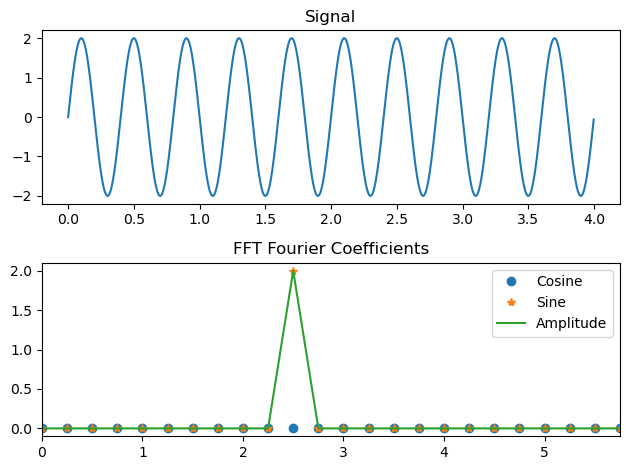

In [7]:
## make some plots

figure(1)

subplot(2,1,1)
plot(t,f)
title('Signal')

subplot(2,1,2)
plot(freq, a, 'o', label='Cosine')
plot(freq, b, '*', label='Sine')
plot(freq, amp, '-', label='Amplitude')
legend()

title('FFT Fourier Coefficients')
xmax = max([f1, f2, f3, f4])*1.15 # find max value and pad a bit (15%)
xlim(0, xmax)

tight_layout() # prevent squished plot (matplotlib kludge)


In [8]:
t=arange(0,10,0.5)
print(t)

[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7.  7.5 8.  8.5
 9.  9.5]


In [9]:
f=sin(2*pi*2/10*t)
print(f)

[ 0.00000000e+00  5.87785252e-01  9.51056516e-01  9.51056516e-01
  5.87785252e-01  1.22464680e-16 -5.87785252e-01 -9.51056516e-01
 -9.51056516e-01 -5.87785252e-01 -2.44929360e-16  5.87785252e-01
  9.51056516e-01  9.51056516e-01  5.87785252e-01  3.67394040e-16
 -5.87785252e-01 -9.51056516e-01 -9.51056516e-01 -5.87785252e-01]


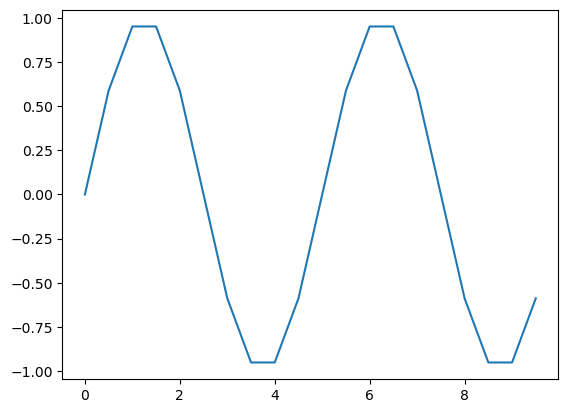

In [10]:
plot(t,f)